In [1]:
import numpy as np
import torch
import math
from torch import nn
import torch.nn.functional as F
from torch import distributions as pyd

from utils import util
import pandas as pd
import matplotlib as mpl
from matplotlib import pyplot as plt
from sklearn.decomposition import NMF

/home/geert/anaconda3/envs/mixer/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


(508, 127)


Text(0.5, 1.0, 'corrcoef 0.89')

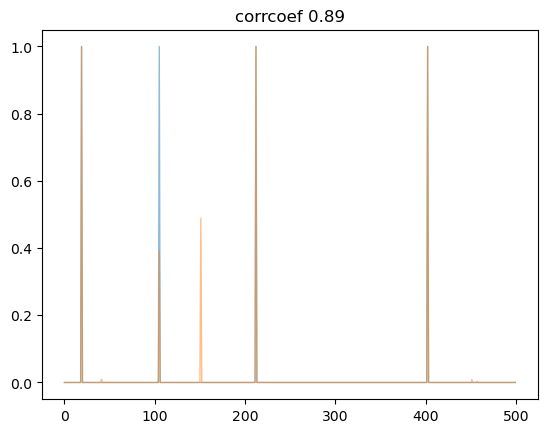

In [17]:
n_state, n_action, n_task = 127, 4, 3
P = np.load('trans_probs.npy').reshape(n_state*n_action, n_state)
print(P.shape)
nmf = NMF(100)
Phi = nmf.fit_transform(P)
Mu = nmf.components_
reconstructed_P = Phi@Mu
plt.plot(P.flatten()[20000:20500], linewidth=1, alpha=0.5)
plt.plot(reconstructed_P.flatten()[20000:20500], linewidth=1, alpha=0.5)
corrcoef = np.corrcoef(P.flatten(), reconstructed_P.flatten())[0,1]
plt.title(f'corrcoef {corrcoef:.2f}')

In [ ]:
R = np.zeros((n_state, n_action, n_task))
R[116,0:3] = 1
R[57,2] = 1

In [3]:
from utils import util, buffer
n_state, n_action, n_task = 9, 4, 9
buffer = torch.load(f'model/RandGridWorld-v0/spedersac/replay_buffer_VI_onehotsa.pkl')
# replay_buffer = buffer.ReplayBuffer(n_state+n_task, n_action, args.buffer_size)
# replay_buffer.load_state_dict(torch.load(f'model/{args.env}/{args.alg}/replay_buffer_VI_onehotsa.pkl'))
# print(f'Replay buffer loaded from model/{args.env}/{args.alg}/replay_buffer_VI_onehotsa.pkl')
# value count
df = {
    'state': np.argmax(replay_buffer.state[:,:n_state], axis=1),
    'action': np.argmax(replay_buffer.action, axis=1),
    'next_state': np.argmax(replay_buffer.next_state[:,:n_state], axis=1),
    'task': np.argmax(replay_buffer.state[:,n_state:], axis=1)
}
import pandas as pd
df = pd.DataFrame(df)
df['s_a_idx'] = df['state']*n_action + df['action']
df = df.groupby(['task']).sum()
print(df)

FileNotFoundError: [Errno 2] No such file or directory: 'model/RandGridWorld-v0/spedersac/replay_buffer_VI_onehotsa.pkl'

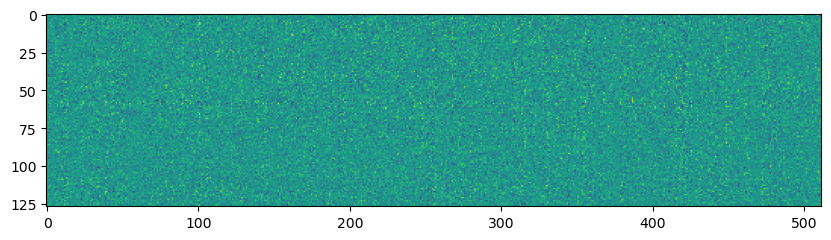

In [ ]:
phi = np.load('./irl_model/labyrinth/spedersac/network_dim512/0/phi_matrix.npy')
mu = np.load('./irl_model/labyrinth/spedersac/network_dim512/0/mu.npy')
fig, ax = plt.subplots(figsize=(10,30))
ax.imshow(phi.reshape(-1,127))
ax.imshow(mu)

In [ ]:
real_P = np.load('trans_probs.npy')
print(real_P.shape)
# print(real_P)
print(np.argmax(real_P[44],1))

(127, 4, 127)
[90 89 21 44]


In [ ]:
dataset = np.load('emissions500new.npy')
segmentation = np.load('learnt_zs_s2.npy')

In [ ]:
print(dataset.shape)
print(segmentation.shape)
# trial * timepoint * s+a  

(238, 500, 2)
(238, 499)


In [ ]:
print(dataset)

[[[ 57   1]
  [116   3]
  [ 57   2]
  ...
  [  6   2]
  [  2   3]
  [  0   3]]

 [[  0   0]
  [  1   1]
  [  4   0]
  ...
  [ 28   0]
  [ 57   1]
  [116   3]]

 [[ 22   2]
  [ 10   1]
  [ 21   1]
  ...
  [ 28   0]
  [ 57   1]
  [116   3]]

 ...

 [[118   2]
  [ 58   1]
  [117   3]
  ...
  [  9   2]
  [  4   3]
  [  1   0]]

 [[  3   0]
  [  8   1]
  [ 17   0]
  ...
  [ 58   1]
  [117   3]
  [ 58   3]]

 [[ 28   1]
  [ 58   1]
  [117   3]
  ...
  [ 49   2]
  [ 24   0]
  [ 49   1]]]


In [4]:
np.unique(dataset[...,1])

NameError: name 'dataset' is not defined

In [5]:
random_buffer = torch.load('./model/labyrinth/spedersac/replay_buffer_labyrinth.pkl')
print(random_buffer.keys())
n_state = 127
n_action = 4
n_task = 3
print(np.argmax(random_buffer['state'][:, :n_state],-1).shape, random_buffer['action'].shape, random_buffer['next_state'].shape)
df = {
    'state_idx': np.argmax(random_buffer['state'][:, :n_state],-1),
    'next_state_idx': np.argmax(random_buffer['next_state'][:, :n_state],-1),
    'action': np.argmax(random_buffer['action'],-1),
    'task': np.argmax(random_buffer['state'][:, n_state:],-1),
}
df = pd.DataFrame(df)
df.to_csv('./model/labyrinth/spedersac/replay_buffer.csv',index=False)


dict_keys(['state', 'action', 'next_state', 'reward', 'done', 'ptr', 'size'])
(118524,) (118524, 4) (118524, 130)


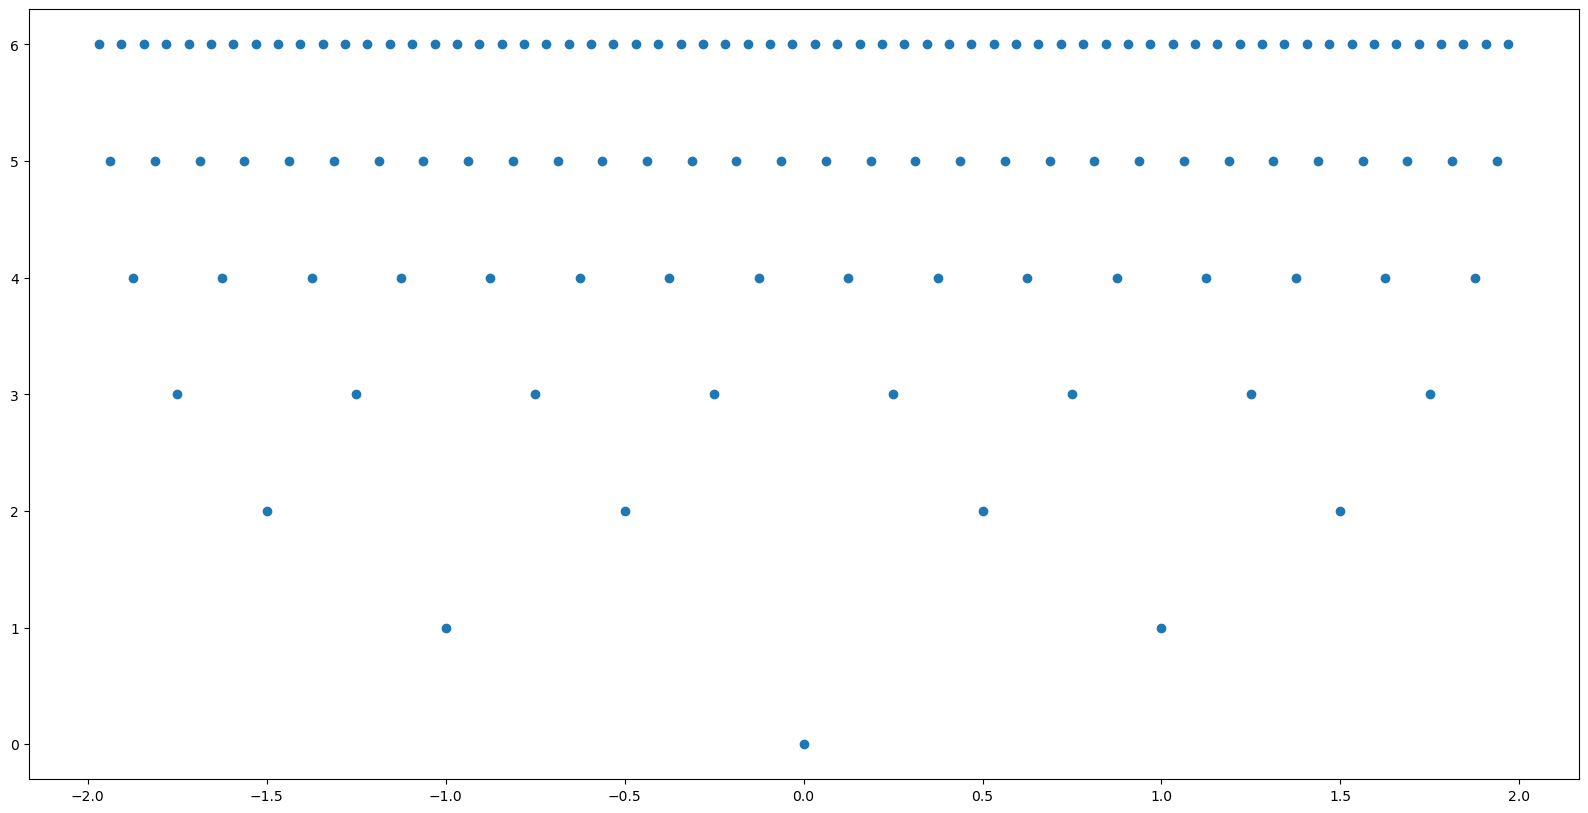

In [6]:
n_state = 127
coordinates = np.zeros((n_state, 2))
def assign_coordinates(index, level, position):
    if index >= n_state:
        return
    y = level
    x = position
    coordinates[index] = (x,y)
    assign_coordinates(2*index+1, level+1, position-1/2**level)
    assign_coordinates(2*index+2, level+1, position+1/2**level)
assign_coordinates(0, 0, 0)
fig, ax = plt.subplots(1,1, figsize=(20,10))
plt.scatter(coordinates[:,0], coordinates[:,1])
    

[14  6 13 ... 28 57 57]
count finished


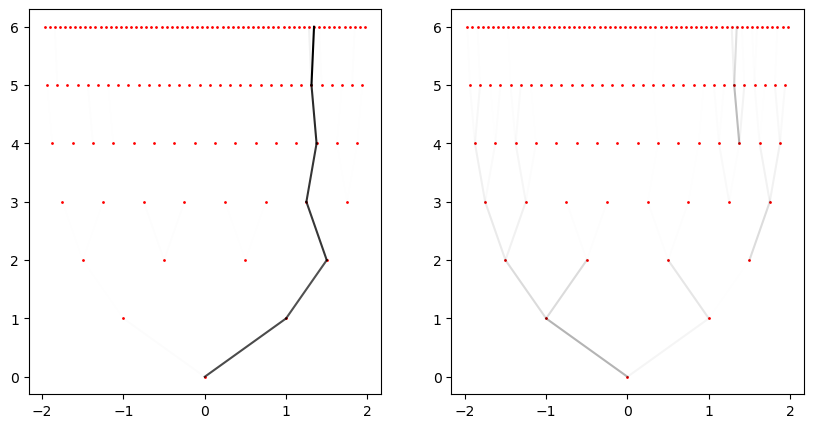

[ 6 28 56 ... 61 30 14]
count finished


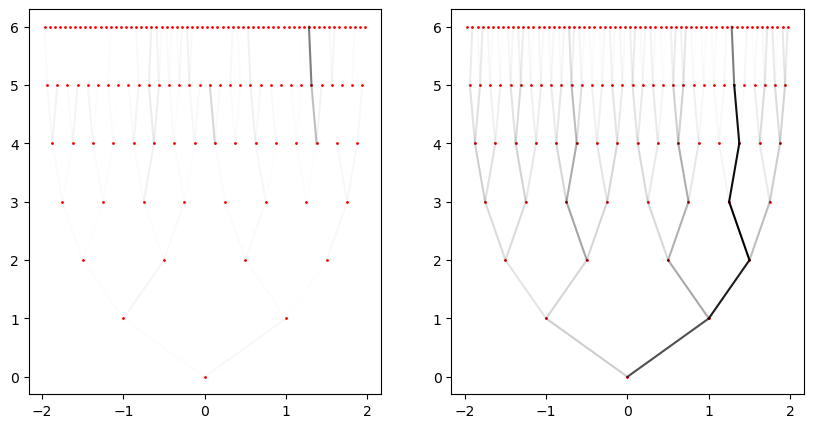

[ 57 116  57 ...  49 100  49]
count finished


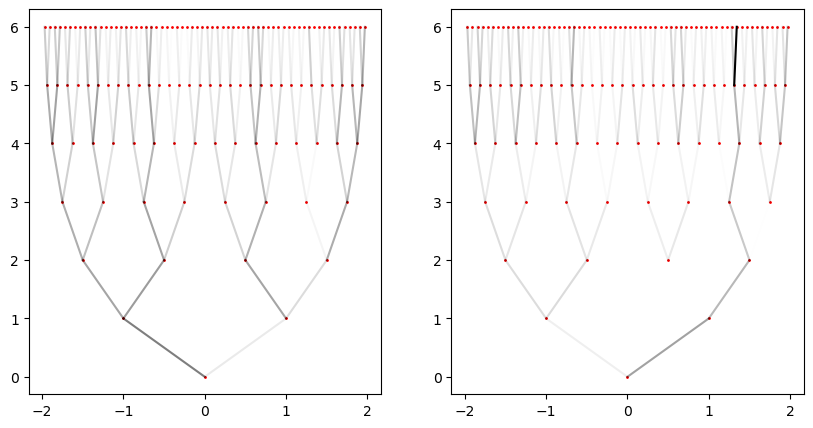

In [7]:

for i in range(3):
    df_task = df[df['task']==i]
    traj = df_task['state_idx'].values
    traj_end = df_task['next_state_idx'].values
    print(traj)
    traj_dir = np.stack([traj, traj_end],-1)
    count = np.zeros((n_state, n_state))
    for q in traj_dir:
        count[q[0], q[1]] += 1
    print('count finished')
    fig, ax = plt.subplots(1,2, figsize=(10,5))
    for j in range(n_state):
        for k in range(n_state):
            if k>=j:
                ax[0].plot([coordinates[j,0], coordinates[k,0]], [coordinates[j,1], coordinates[k,1]], 'k', alpha=count[j,k]/np.max(count))

            else:
                ax[1].plot([coordinates[j,0], coordinates[k,0]], [coordinates[j,1], coordinates[k,1]], 'k', alpha=count[j,k]/np.max(count))
                
    ax[0].scatter(coordinates[:,0], coordinates[:,1], c='r', s=1)
    ax[1].scatter(coordinates[:,0], coordinates[:,1], c='r', s=1)
        # plt.plot(coordinates[q,0], coordinates[q,1], 'r', alpha=0.01)
    plt.show()


In [38]:
import numpy as np
import torch
import gym
import argparse
import os
import pickle
import visualize
from tensorboardX import SummaryWriter
from utils import util, buffer
from agent.spedersac import spedersac_iragent
import pandas as pd

def one_hot(idx, depth):
    return np.eye(depth)[idx]

state_dim = 127
action_dim = 4
n_task = 3
buffer_size = dataset.shape[0] * (dataset.shape[1]-1)
replay_buffer = buffer.ReplayBuffer(state_dim+n_task, action_dim, buffer_size)
state_ar = np.eye(state_dim)
action_ar = np.eye(action_dim)
task_id_ar = np.eye(n_task)
r = np.zeros(1,)
done = np.zeros(1,)
for i in range(dataset.shape[0]):
    for j in range(dataset.shape[1]-2):
        state_onehot = state_ar[dataset[i,j,0]]
        task_id_onehot = task_id_ar[segmentation[i,j]]
        full_state_onehot = np.concatenate([state_onehot, task_id_onehot],-1)
        action_onehot = action_ar[dataset[i,j,1]]
        next_state_onehot = state_ar[dataset[i,j+1,0]]
        next_task_id_onehot = task_id_ar[segmentation[i,j+1]]
        full_next_state_onehot = np.concatenate([next_state_onehot, next_task_id_onehot],-1)
        replay_buffer.add(full_state_onehot, action_onehot, full_next_state_onehot, r, done)

In [40]:
torch.save(replay_buffer.state_dict(), './replay_buffer_labyrinth.pkl')

In [43]:
torch.load('./replay_buffer_random_labyrinth.pkl')

{'state': array([[0., 0., 0., ..., 1., 0., 0.],
        [0., 0., 0., ..., 1., 0., 0.],
        [0., 0., 0., ..., 1., 0., 0.],
        ...,
        [0., 0., 0., ..., 1., 0., 0.],
        [0., 0., 0., ..., 1., 0., 0.],
        [0., 0., 0., ..., 1., 0., 0.]]),
 'action': array([[0., 0., 0., 1.],
        [0., 1., 0., 0.],
        [1., 0., 0., 0.],
        ...,
        [1., 0., 0., 0.],
        [0., 1., 0., 0.],
        [0., 0., 0., 1.]]),
 'next_state': array([[0., 0., 0., ..., 1., 0., 0.],
        [0., 0., 0., ..., 1., 0., 0.],
        [0., 0., 0., ..., 1., 0., 0.],
        ...,
        [0., 0., 0., ..., 1., 0., 0.],
        [0., 0., 0., ..., 1., 0., 0.],
        [0., 0., 0., ..., 1., 0., 0.]]),
 'reward': array([[0.],
        [0.],
        [0.],
        ...,
        [0.],
        [0.],
        [0.]]),
 'done': array([[0.],
        [0.],
        [0.],
        ...,
        [0.],
        [0.],
        [0.]]),
 'ptr': 0,
 'size': 90000}

In [5]:
import numpy as np
import torch
import gym
import argparse
import os
import pickle
import visualize

from tensorboardX import SummaryWriter

from utils import util, buffer
# from agent.sac import sac_agent
# from agent.vlsac import vlsac_agent
# from agent.ctrlsac import ctrlsac_agent
# from agent.diffsrsac import diffsrsac_agent
# from agent.spedersac import spedersac_agent
from agent.spedersac import spedersac_iragent
import pandas as pd

model_path = f'irl_model/RandomGridWorld-v0/spedersac/3x3-f64-onehotsa/0'
state_dim = 2
action_dim = 1
buffer_size = 10000
replay_buffer = buffer.ReplayBuffer(state_dim, action_dim, buffer_size)
buffer_path = model_path.replace('irl_model', 'model')
replay_buffer.load_state_dict(torch.load(f'{buffer_path}/replay_buffer_task1.pkl'))
print(type(replay_buffer))
df = pd.DataFrame({
    'task': np.argmax(replay_buffer.state[:,2:], axis=1),
    'state_i': replay_buffer.state[:,0].astype(int),
    'state_j': replay_buffer.state[:,1].astype(int),
    'action': replay_buffer.action[:,0].astype(int),
    'next_state_i': replay_buffer.next_state[:,0].astype(int),
    'next_state_j': replay_buffer.next_state[:,1].astype(int),
    'reward': replay_buffer.reward[:,0],
    'done': replay_buffer.done[:,0].astype(int)
})
# df.to_csv(f'{buffer_path}/replay_buffer.csv')

<class 'utils.buffer.ReplayBuffer'>


In [6]:
for i in range(9):
    replay_buffer.load_state_dict(torch.load(f'{buffer_path}/replay_buffer_task{i}.pkl'))
    task_id = np.argmax(replay_buffer.state[:,2:], axis=1)
    occupancy = np.zeros((9,))
    for j in range(9):
        occupancy[j] = np.where(task_id == j,1,0).mean()
    print(i, occupancy)
    df = pd.DataFrame({
    'task': np.argmax(replay_buffer.state[:,2:], axis=1),
    'state_i': replay_buffer.state[:,0].astype(int),
    'state_j': replay_buffer.state[:,1].astype(int),
    'action': replay_buffer.action[:,0].astype(int),
    'next_state_i': replay_buffer.next_state[:,0].astype(int),
    'next_state_j': replay_buffer.next_state[:,1].astype(int),
    'reward': replay_buffer.reward[:,0],
    'done': replay_buffer.done[:,0].astype(int)
    })
    df.to_csv(f'{buffer_path}/replay_buffer_task{i}.csv')

0 [1. 0. 0. 0. 0. 0. 0. 0. 0.]
1 [0. 1. 0. 0. 0. 0. 0. 0. 0.]
2 [0. 0. 1. 0. 0. 0. 0. 0. 0.]
3 [0. 0. 0. 1. 0. 0. 0. 0. 0.]
4 [0. 0. 0. 0. 1. 0. 0. 0. 0.]
5 [0. 0. 0. 0. 0. 1. 0. 0. 0.]
6 [0. 0. 0. 0. 0. 0. 1. 0. 0.]
7 [0. 0. 0. 0. 0. 0. 0. 1. 0.]
8 [0. 0. 0. 0. 0. 0. 0. 0. 1.]


In [18]:
np.random.randint(0,9,1)

array([5])

In [25]:
grid_col, grid_row = np.meshgrid(np.arange(3), np.arange(3))
xy = np.array([grid_row.reshape(-1),grid_col.reshape(-1)]).T
print(xy)

[[0 0]
 [0 1]
 [0 2]
 [1 0]
 [1 1]
 [1 2]
 [2 0]
 [2 1]
 [2 2]]


In [9]:
# task_id = df['task']
n_task = 9
state = np.zeros((buffer_size*9, 2+n_task))
action = np.zeros((buffer_size*9, 1))
next_state = np.zeros((buffer_size*9, 2+n_task))
reward = np.zeros((buffer_size*9, 1))
done = np.zeros((buffer_size*9, 1))
for i in range(9):
    replay_buffer.load_state_dict(torch.load(f'{buffer_path}/replay_buffer_task{i}.pkl'))
    state[i*buffer_size:(i+1)*buffer_size] = replay_buffer.state
    action[i*buffer_size:(i+1)*buffer_size] = replay_buffer.action[:,0:1]
    next_state[i*buffer_size:(i+1)*buffer_size] = replay_buffer.next_state
    reward[i*buffer_size:(i+1)*buffer_size] = replay_buffer.reward
    done[i*buffer_size:(i+1)*buffer_size] = replay_buffer.done
replay_buffer = buffer.ReplayBuffer(state_dim, action_dim, buffer_size*9)
replay_buffer.state = state
replay_buffer.action = action
replay_buffer.next_state = next_state
replay_buffer.reward = reward
replay_buffer.done = done
replay_buffer.ptr = buffer_size*9
replay_buffer.size = buffer_size*9
torch.save(replay_buffer.state_dict(), f'{buffer_path}/replay_buffer_balance.pkl')
occupancy = np.zeros((9,))
task_id = np.argmax(replay_buffer.state[:,2:], axis=1)
for j in range(9):
    occupancy[j] = np.where(task_id == j,1,0).mean()
print(occupancy)

[0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1 0.1]


In [3]:
n_width = 3
n_height = 3
n_action = 4
grid_col, grid_row = np.meshgrid(np.arange(n_width), np.arange(n_height))
states = np.concatenate([grid_row.reshape(-1,1), grid_col.reshape(-1,1)], axis=-1)
n_state = n_height * n_width
n_task = n_state
state_action_pairs = np.concatenate([np.repeat(states, n_action, axis=0), np.tile(np.arange(n_action).reshape(-1,1), (states.shape[0],1))], axis=-1)
print(state_action_pairs)

[[0 0 0]
 [0 0 1]
 [0 0 2]
 [0 0 3]
 [0 1 0]
 [0 1 1]
 [0 1 2]
 [0 1 3]
 [0 2 0]
 [0 2 1]
 [0 2 2]
 [0 2 3]
 [1 0 0]
 [1 0 1]
 [1 0 2]
 [1 0 3]
 [1 1 0]
 [1 1 1]
 [1 1 2]
 [1 1 3]
 [1 2 0]
 [1 2 1]
 [1 2 2]
 [1 2 3]
 [2 0 0]
 [2 0 1]
 [2 0 2]
 [2 0 3]
 [2 1 0]
 [2 1 1]
 [2 1 2]
 [2 1 3]
 [2 2 0]
 [2 2 1]
 [2 2 2]
 [2 2 3]]


In [5]:
state_action_pair_idx = (state_action_pairs[:,0]*n_width + state_action_pairs[:,1])*n_action + state_action_pairs[:,2]
print(state_action_pair_idx)

[ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23
 24 25 26 27 28 29 30 31 32 33 34 35]


In [31]:
task_id = np.argmax(buffer['state'][:,state_dim:], axis=1)
occupancy = np.zeros((n_task,))
for j in range(n_task):
    occupancy[j] = np.where(task_id == j,1,0).mean()
print(occupancy)

[0.2 0.2 0.6]


In [30]:
import pandas as pd
buffer = torch.load('./replay_buffer_labyrinth.npy')
print(buffer['state'].shape)

(118524, 131)


In [21]:
import pandas as pd
buffer = torch.load('./replay_buffer_VI.pkl')
print(buffer['state'].shape)
# convert to DataFrame
df = pd.DataFrame({
    'task': np.argmax(buffer['state'][:,2:], axis=1),
    'state_i': buffer['state'][:,0].astype(int),
    'state_j': buffer['state'][:,1].astype(int),
    'action': buffer['action'][:,0].astype(int),
    'next_state_i': buffer['next_state'][:,0].astype(int),
    'next_state_j': buffer['next_state'][:,1].astype(int),
    'reward': buffer['reward'][:,0],
    'done': buffer['done'][:,0].astype(int)
})
df.to_csv('./replay_buffer_VI.csv')


In [24]:
print(df[(df['state_i']==0) & (df['state_j']==0) & (df['action']==0) & (df['task']==2)].shape)
print(df.shape)
occupancy = np.zeros((9,))
task_id = np.argmax(buffer['state'][:,2:], axis=1)
for j in range(9):
    occupancy[j] = np.where(task_id == j,1,0).mean()
print(occupancy)

(445, 8)
(90000, 8)
[0.13661111 0.08794444 0.15526667 0.14611111 0.08668889 0.11876667
 0.05198889 0.06104444 0.15557778]


In [13]:
from torch.nn import functional as F
F.onehot(torch.tensor([1,2,3]), 4)

AttributeError: module 'torch.nn.functional' has no attribute 'onehot'

In [10]:
from agent.spedersac import spedersac_iragent
import visualize
feature_dim = 9
n_width = 3
n_action = 4
n_task = 9
phi = spedersac_iragent.SingleMatrixFixedPhi(n_width, n_action, feature_dim)
phi.load_state_dict({'matrix.weight': torch.FloatTensor(np.load('Phi.npy'))})
print(phi.matrix.weight.shape)
phi_matrix = np.load('Phi.npy')
mu = spedersac_iragent.SingleMatrixFixedMu(n_width, feature_dim)
mu.load_state_dict({'matrix.weight': torch.FloatTensor(np.load('Mu.npy'))})
mu_matrix = np.load('Mu.npy')
print(mu.matrix.weight.shape)
r = np.load('r.npy').reshape(-1, n_task)
print(np.isclose(phi_matrix@(np.linalg.pinv(phi_matrix)@r),r).all())




torch.Size([36, 9])
torch.Size([9, 9])
True


In [2]:
import torch
n_width = n_height = 3
grid_col, grid_row = torch.meshgrid(torch.arange(0, n_width), torch.arange(0, n_height), indexing='xy')
states_all = torch.concat([grid_row.reshape(-1, 1), grid_col.reshape(-1, 1)], -1).float()
actions_all = torch.tensor([[-1,0],[1,0],[0,1],[0,-1]])
state_action_pairs = torch.concat([torch.repeat_interleave(states_all, actions_all.shape[0], dim=0), torch.tile(actions_all, (states_all.shape[0], 1))], -1)
print(state_action_pairs)

tensor([[ 0.,  0., -1.,  0.],
        [ 0.,  0.,  1.,  0.],
        [ 0.,  0.,  0.,  1.],
        [ 0.,  0.,  0., -1.],
        [ 0.,  1., -1.,  0.],
        [ 0.,  1.,  1.,  0.],
        [ 0.,  1.,  0.,  1.],
        [ 0.,  1.,  0., -1.],
        [ 0.,  2., -1.,  0.],
        [ 0.,  2.,  1.,  0.],
        [ 0.,  2.,  0.,  1.],
        [ 0.,  2.,  0., -1.],
        [ 1.,  0., -1.,  0.],
        [ 1.,  0.,  1.,  0.],
        [ 1.,  0.,  0.,  1.],
        [ 1.,  0.,  0., -1.],
        [ 1.,  1., -1.,  0.],
        [ 1.,  1.,  1.,  0.],
        [ 1.,  1.,  0.,  1.],
        [ 1.,  1.,  0., -1.],
        [ 1.,  2., -1.,  0.],
        [ 1.,  2.,  1.,  0.],
        [ 1.,  2.,  0.,  1.],
        [ 1.,  2.,  0., -1.],
        [ 2.,  0., -1.,  0.],
        [ 2.,  0.,  1.,  0.],
        [ 2.,  0.,  0.,  1.],
        [ 2.,  0.,  0., -1.],
        [ 2.,  1., -1.,  0.],
        [ 2.,  1.,  1.,  0.],
        [ 2.,  1.,  0.,  1.],
        [ 2.,  1.,  0., -1.],
        [ 2.,  2., -1.,  0.],
        [ 

In [27]:
import numpy as np
a = np.eye(9).reshape(3,3,9)
print(a[1,0])

[0. 0. 0. 1. 0. 0. 0. 0. 0.]
